# Clustering

This notebook selects clustering parameters and compares K-Means and Leiden on the saved PCA and autoencoder embeddings. It does not read reference cell-type labels.

In [1]:
import os

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import seaborn as sns
import umap
import yaml
from anndata import read_h5ad
from IPython.display import display

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

with open('configs/default.yml') as file:
    config = yaml.safe_load(file)

settings = config['clustering']
representation_settings = config['representation']
seed = config['analysis']['random_seed']
sample_order = config['dataset']['selected_samples']
latent_dim = representation_settings['latent_dim']
figure_dir = 'outputs/figures'

os.makedirs(figure_dir, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')

/Users/ren/anaconda3/envs/lung-tumor-cell-type-identification/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Candidate diagnostics and hyperparameter selection

Each table shows the candidate results for one representation and clustering method. The final parameters were selected from silhouette, cluster count, and cluster-size diagnostics.

In [2]:
diagnostics = pd.read_csv('outputs/tables/clustering-parameter-diagnostics.csv')
columns = ['parameter', 'n_clusters', 'silhouette_score', 'min_cluster_size', 'median_cluster_size', 'runtime_seconds']

for representation, method, title in [
    ('pca', 'kmeans', 'PCA + K-Means'),
    ('autoencoder', 'kmeans', 'Autoencoder + K-Means'),
    ('pca', 'leiden', 'PCA + Leiden'),
    ('autoencoder', 'leiden', 'Autoencoder + Leiden')
]:
    print(title)
    table = diagnostics.loc[(diagnostics['representation'] == representation) & (diagnostics['method'] == method), columns]
    display(table.sort_values('parameter').round(4))

PCA + K-Means


,parameter,n_clusters,silhouette_score,min_cluster_size,median_cluster_size,runtime_seconds
0,6.0,6,0.3550,1807,6109.0,0.3232
1,8.0,8,0.3052,1804,5366.5,0.2660
2,10.0,10,0.3039,633,3548.5,0.3189
3,12.0,12,0.3194,632,2576.0,0.3685


Autoencoder + K-Means


,parameter,n_clusters,silhouette_score,min_cluster_size,median_cluster_size,runtime_seconds
9,6.0,6,0.2367,2334,7475.0,0.3078
10,8.0,8,0.2494,1821,4931.0,0.3256
11,10.0,10,0.2442,644,3571.5,0.4170
12,12.0,12,0.2191,644,2638.5,0.4237


PCA + Leiden


,parameter,n_clusters,silhouette_score,min_cluster_size,median_cluster_size,runtime_seconds
4,0.2,13,0.2143,636,1803.0,3.1679
5,0.4,17,0.2434,636,1816.0,3.8955
6,0.6,20,0.2258,388,1724.5,4.1294
7,0.8,24,0.2215,105,1389.5,5.0963
8,1.0,27,0.2329,301,1434.0,9.7679


Autoencoder + Leiden


,parameter,n_clusters,silhouette_score,min_cluster_size,median_cluster_size,runtime_seconds
13,0.2,14,0.2048,23,1737.5,4.2152
14,0.4,21,0.1734,23,1668.0,5.4431
15,0.6,29,0.1505,23,972.0,3.7098
16,0.8,32,0.1620,23,793.0,9.9392
17,1.0,41,0.1591,23,710.0,7.7143


Based on the candidate diagnostics, the final clustering parameters are:

- PCA + K-Means: K = 6
- Autoencoder + K-Means: K = 8
- PCA + Leiden: resolution = 0.4 (n_clusters = 17)
- Autoencoder + Leiden: resolution = 0.2 (n_clusters = 16)

## Clustering results

After selecting a shared K and Leiden resolution, we can generate the four final assignments and the figures below.

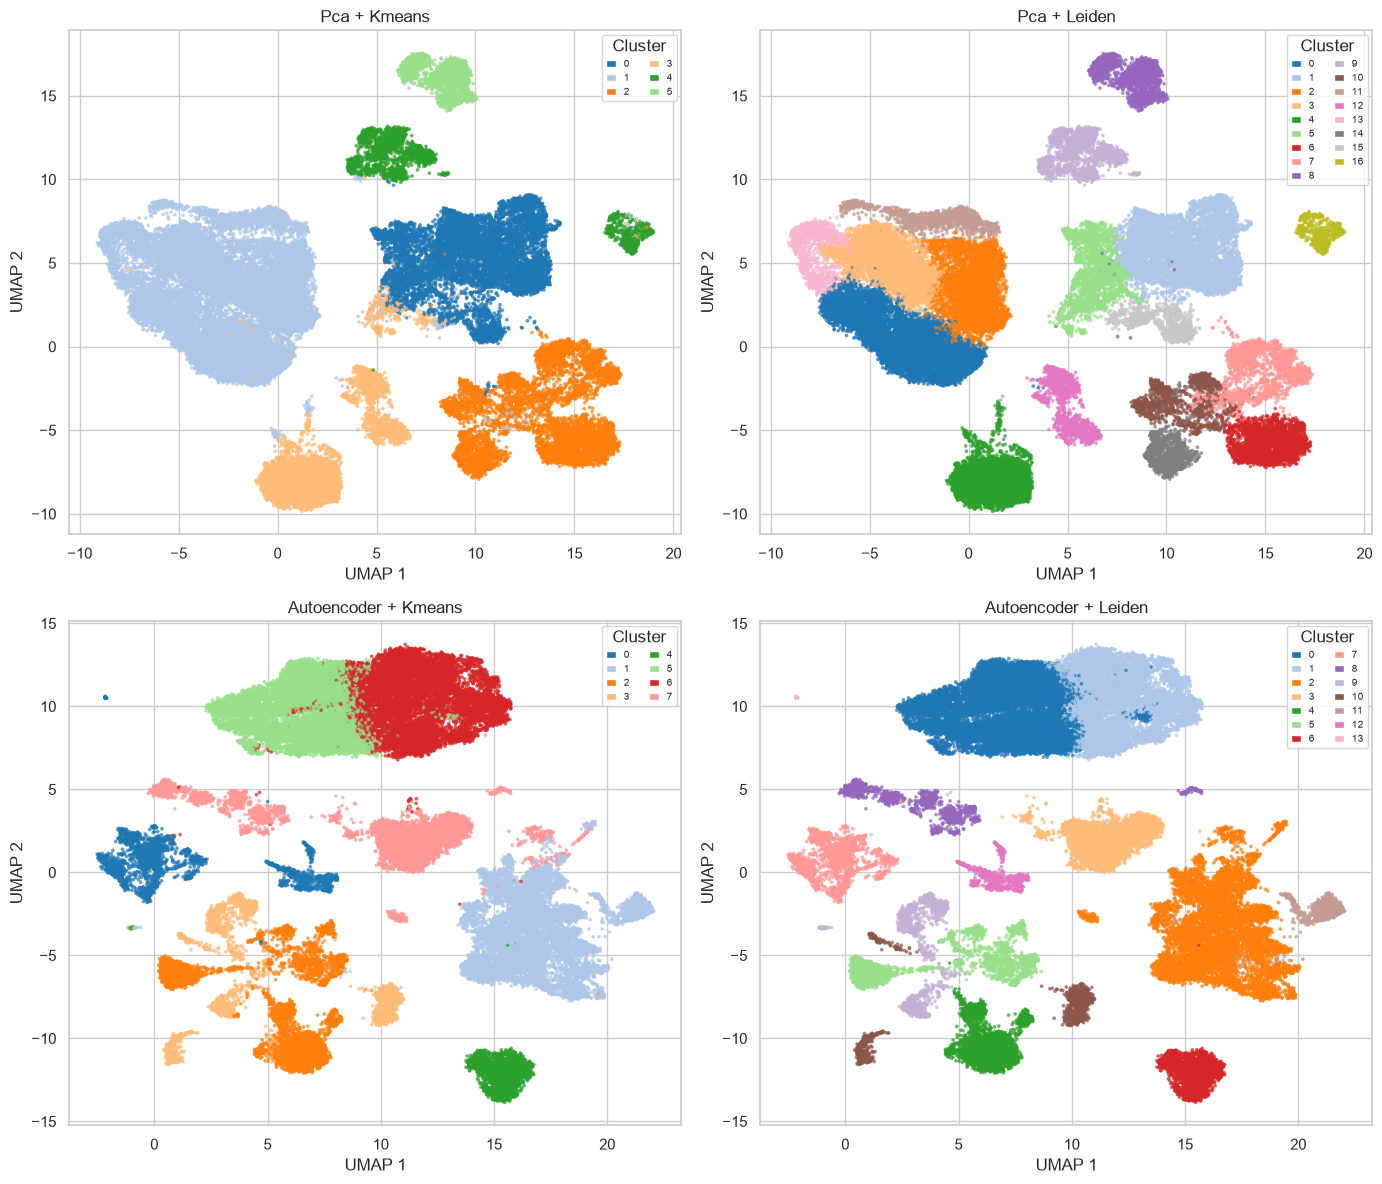

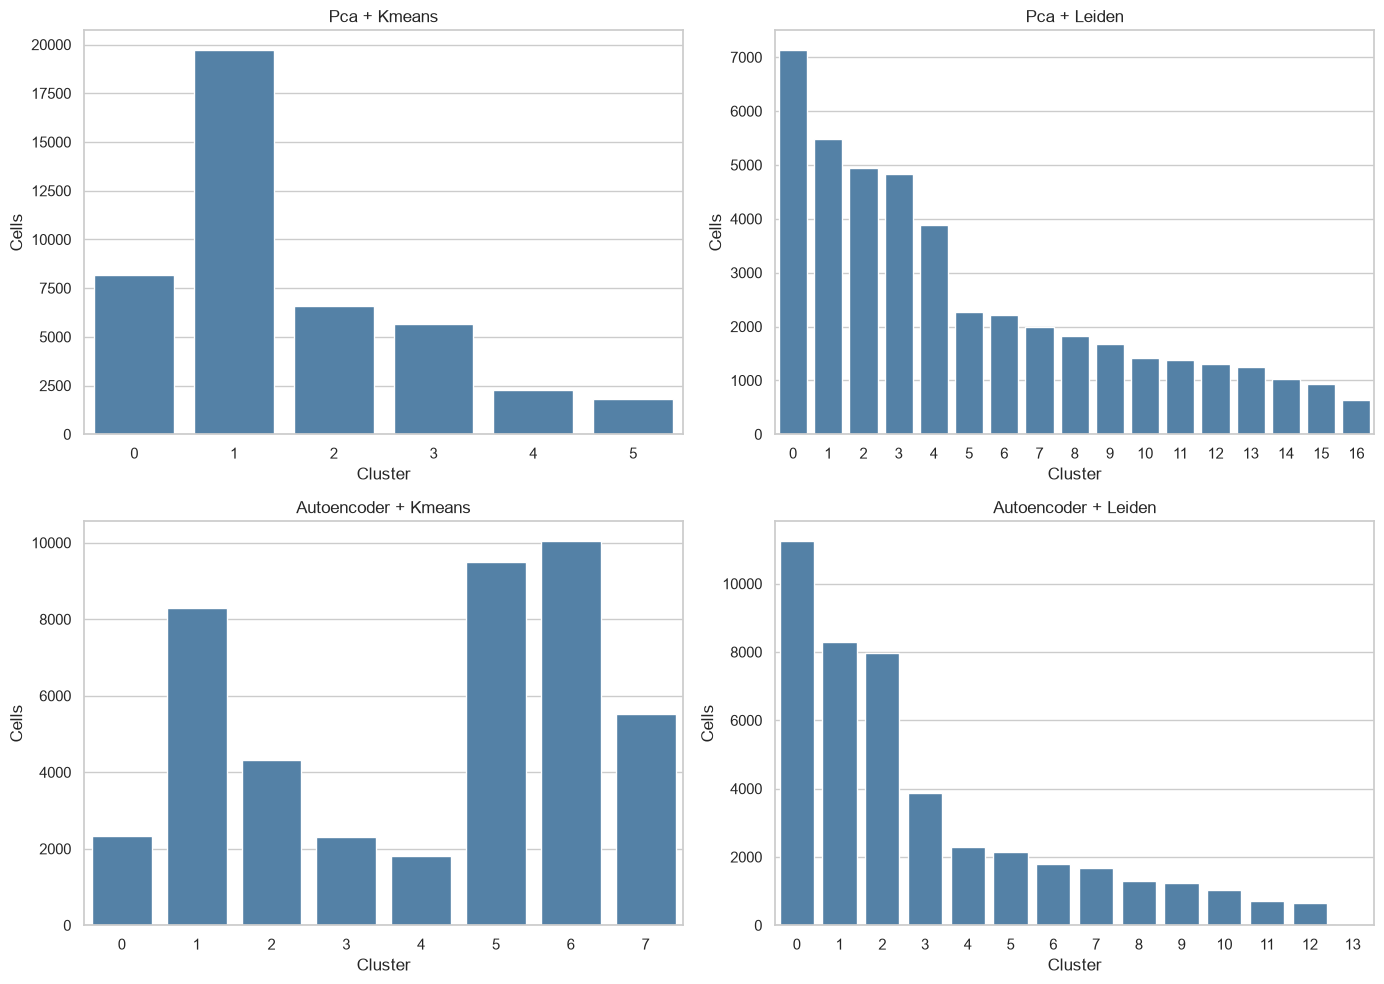

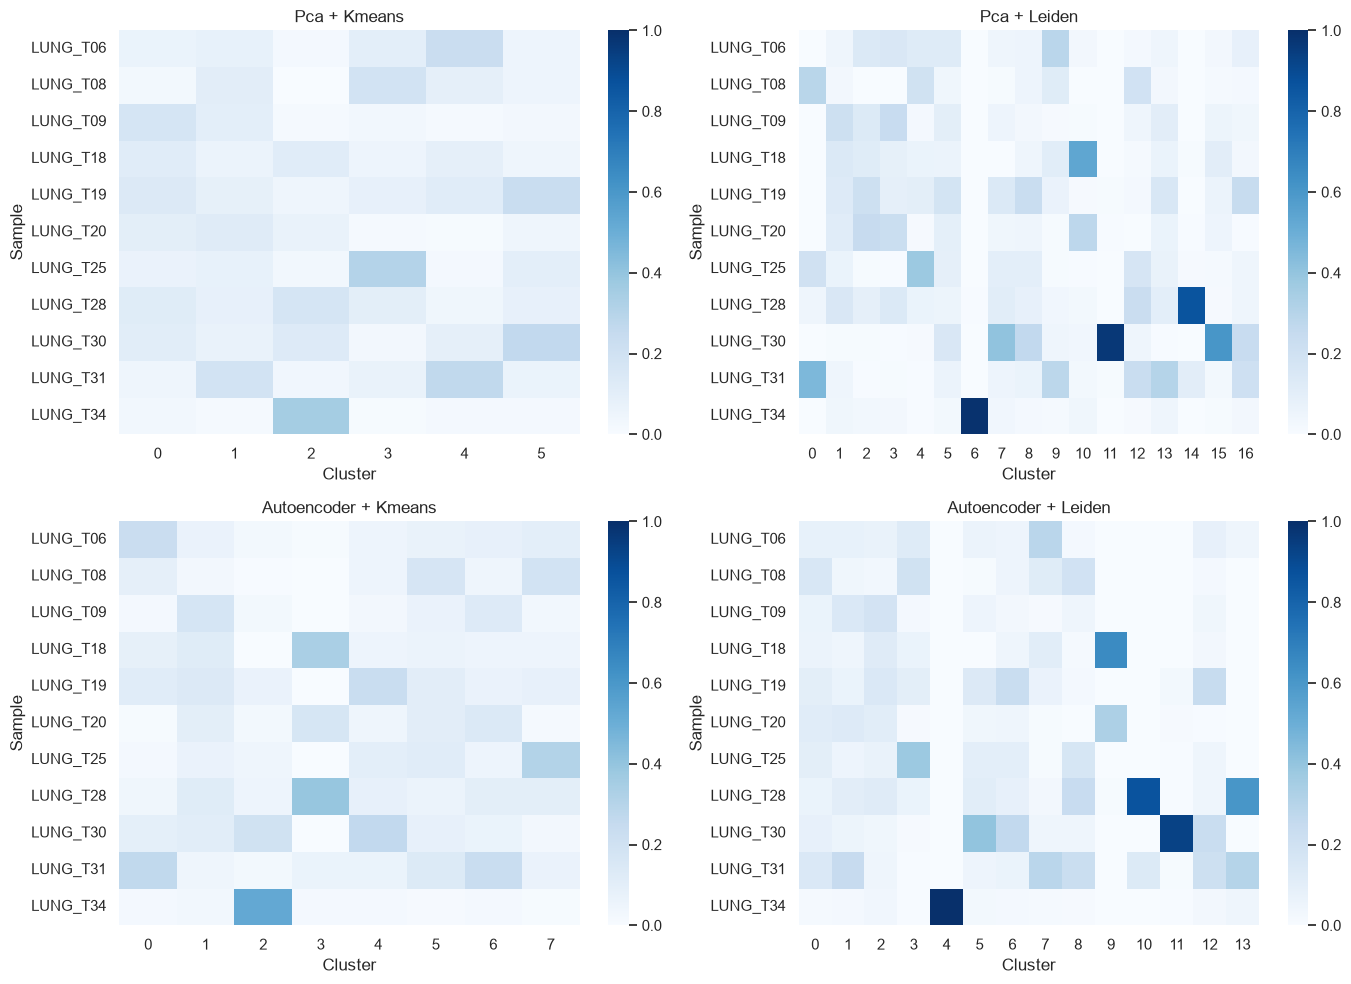

In [3]:
final_parameters = settings['final_parameters']

if final_parameters:
    metadata = read_h5ad('data/processed/lung_tumor_hvg.h5ad', backed='r').obs[['sample']].copy()
    metadata['sample'] = pd.Categorical(metadata['sample'], categories=sample_order, ordered=True)
    labels = pd.read_csv('outputs/clusters/clustering-labels.csv.gz', index_col='cell_id').loc[metadata.index]
    pca_embedding = pd.read_csv(f'outputs/embeddings/pca-{latent_dim}.csv.gz', index_col='cell_id').loc[metadata.index]
    autoencoder_embedding = pd.read_csv(f'outputs/embeddings/autoencoder-{latent_dim}.csv.gz', index_col='cell_id').loc[metadata.index]

    def calculate_umap(embedding):
        reducer = umap.UMAP(
            n_neighbors=representation_settings['umap_n_neighbors'],
            min_dist=representation_settings['umap_min_dist'],
            random_state=seed,
            n_jobs=1,
            compatibility_layout=True
        )
        return reducer.fit_transform(embedding)

    def numeric_cluster_order(cluster_labels):
        return sorted(cluster_labels.astype(str).unique(), key=int)

    coordinates = {
        'pca': calculate_umap(pca_embedding),
        'autoencoder': calculate_umap(autoencoder_embedding)
    }
    specifications = [
        ('pca', 'kmeans'), ('pca', 'leiden'),
        ('autoencoder', 'kmeans'), ('autoencoder', 'leiden')
    ]

    figure, axes = plt.subplots(2, 2, figsize=(14, 12))
    for axis, (representation, method) in zip(axes.flat, specifications):
        cluster_labels = labels[f'{representation}_{method}'].astype(str)
        cluster_order = numeric_cluster_order(cluster_labels)
        colors = dict(zip(cluster_order, sns.color_palette('tab20', cluster_labels.nunique())))
        axis.scatter(coordinates[representation][:, 0], coordinates[representation][:, 1], c=cluster_labels.map(colors), s=3, alpha=0.6)
        handles = [Patch(facecolor=colors[label], label=label) for label in cluster_order]
        axis.legend(handles=handles, title='Cluster', loc='best', fontsize=7, ncol=2, handlelength=1)
        axis.set_title(f'{representation.title()} + {method.title()}')
        axis.set_xlabel('UMAP 1')
        axis.set_ylabel('UMAP 2')
    figure.tight_layout()
    figure.savefig(os.path.join(figure_dir, 'clustering_cluster-umap.png'), dpi=300, bbox_inches='tight')
    plt.show()

    figure, axes = plt.subplots(2, 2, figsize=(14, 10))
    for axis, (representation, method) in zip(axes.flat, specifications):
        cluster_labels = labels[f'{representation}_{method}'].astype(str)
        cluster_order = numeric_cluster_order(cluster_labels)
        cluster_sizes = cluster_labels.value_counts().reindex(cluster_order)
        sns.barplot(x=cluster_sizes.index, y=cluster_sizes.values, color='steelblue', ax=axis)
        axis.set_title(f'{representation.title()} + {method.title()}')
        axis.set_xlabel('Cluster')
        axis.set_ylabel('Cells')
    figure.tight_layout()
    figure.savefig(os.path.join(figure_dir, 'clustering_cluster-size-distributions.png'), dpi=300, bbox_inches='tight')
    plt.show()

    figure, axes = plt.subplots(2, 2, figsize=(14, 10))
    for axis, (representation, method) in zip(axes.flat, specifications):
        cluster_labels = labels[f'{representation}_{method}'].astype(str)
        cluster_order = numeric_cluster_order(cluster_labels)
        composition = pd.crosstab(cluster_labels, metadata['sample'], normalize='index')
        composition = composition.reindex(index=cluster_order, columns=sample_order, fill_value=0)
        sns.heatmap(composition.T, cmap='Blues', vmin=0, vmax=1, ax=axis)
        axis.set_title(f'{representation.title()} + {method.title()}')
        axis.set_xlabel('Cluster')
        axis.set_ylabel('Sample')
    figure.tight_layout()
    figure.savefig(os.path.join(figure_dir, 'clustering_sample-composition.png'), dpi=300, bbox_inches='tight')
    plt.show()